<a href="https://colab.research.google.com/github/FardinLakdawala/prml-assigments/blob/main/prml_2_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Correlation Analysis for Advertising and Housing Datasets
We will start by loading both datasets, inspecting them, encoding categorical variables if any, and computing the correlation matrix to see which features we can drop.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the datasets
adv_df = pd.read_csv('/content/advertising.csv')
house_df = pd.read_csv('/content/Housing.csv')

# Display the first few rows of Advertising dataset
print("--- Advertising Dataset Head ---")
display(adv_df.head())

# Display the first few rows of Housing dataset
print("\n--- Housing Dataset Head ---")
display(house_df.head())

--- Advertising Dataset Head ---


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9



--- Housing Dataset Head ---


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


### Question 2: Correlation Analysis & Feature Dropping
Let's calculate correlation matrices. For the Housing dataset, we must first map string categorical columns (like 'yes'/'no' and furnishing status) to numbers so we can compute correlation.

--- Advertising Correlation with Sales ---


,Sales
TV,0.901208
Radio,0.349631
Newspaper,0.157960
Sales,1.000000


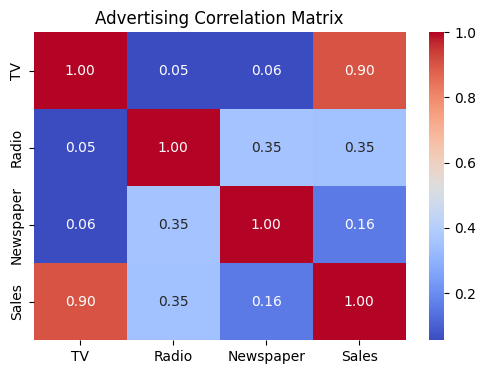


--- Housing Correlation with Price ---


,price
price,1.000000
area,0.535997
bedrooms,0.366494
bathrooms,0.517545
stories,0.420712
mainroad,0.296898
guestroom,0.255517
basement,0.187057
hotwaterheating,0.093073
airconditioning,0.452954


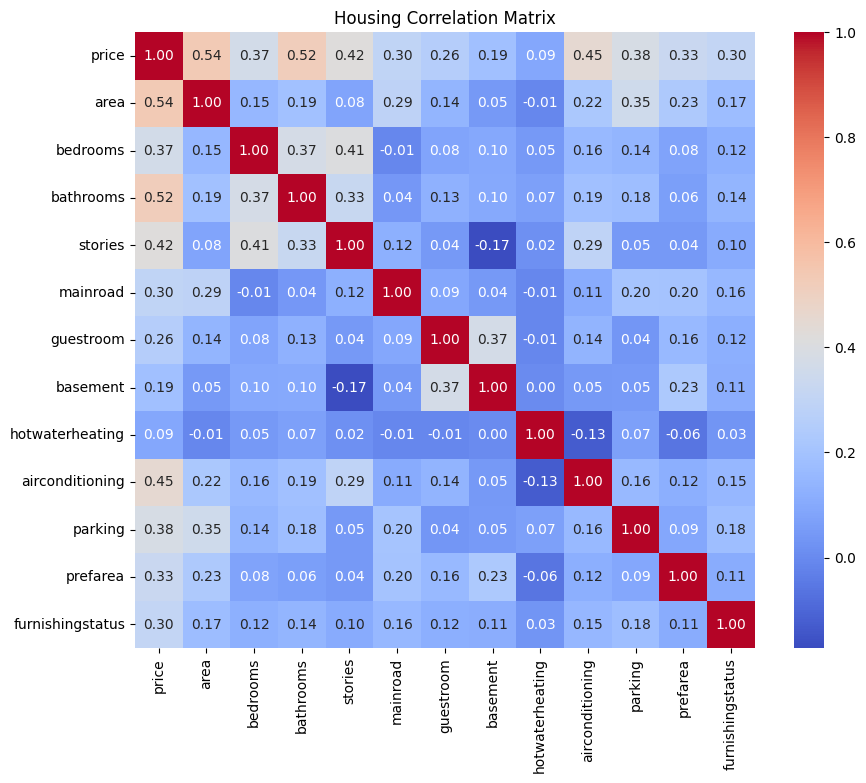

In [ ]:
# 1. Advertising dataset correlation
# Target is typically 'Sales'
print("--- Advertising Correlation with Sales ---")
adv_corr = adv_df.corr()
display(adv_corr['Sales'])

# Plot correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(adv_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Advertising Correlation Matrix')
plt.show()

# 2. Housing dataset correlation
# Convert categorical variables to numeric binaries/integers
house_numeric = house_df.copy()
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_cols:
    house_numeric[col] = house_numeric[col].map({'yes': 1, 'no': 0})

# Map furnishingstatus to integers
house_numeric['furnishingstatus'] = house_numeric['furnishingstatus'].map({'furnished': 2, 'semi-furnished': 1, 'unfurnished': 0})

print("\n--- Housing Correlation with Price ---")
house_corr = house_numeric.corr()
display(house_corr['price'])

# Plot correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(house_corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Housing Correlation Matrix')
plt.show()

### Question 3: Design Linear Regression Model
We will implement a simple Linear Regression class using numpy (Normal Equation) to keep it simple, transparent, and compliant with the restrictions. We will split both datasets (80% train, 20% test), train models, and compute $R^2$, MAE, and MSE.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 1. Train & Evaluate Advertising Model ---
X_adv = adv_df.drop(columns=['Sales'])
y_adv = adv_df['Sales']
# Split the data 80:20
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(X_adv, y_adv, test_size=0.2, random_state=42)

# Instantiate and fit the model
model_adv = LinearRegression()
model_adv.fit(X_train_adv, y_train_adv)

# Make predictions
preds_adv = model_adv.predict(X_test_adv)

# Calculate metrics
r2_adv = r2_score(y_test_adv, preds_adv)
mae_adv = mean_absolute_error(y_test_adv, preds_adv)
mse_adv = mean_squared_error(y_test_adv, preds_adv)

print("--- Advertising Linear Regression Performance ---")
print(f"R2 Score: {r2_adv:.4f}")
print(f"MAE: {mae_adv:.4f}")
print(f"MSE: {mse_adv:.4f}")

# --- 2. Train & Evaluate Housing Model ---
X_house = house_numeric.drop(columns=['price'])
y_house = house_numeric['price']
# Split the data 80:20
X_train_house, X_test_house, y_train_house, y_test_house = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

# Instantiate and fit the model
model_house = LinearRegression()
model_house.fit(X_train_house, y_train_house)

# Make predictions
preds_house = model_house.predict(X_test_house)

# Calculate metrics
r2_house = r2_score(y_test_house, preds_house)
mae_house = mean_absolute_error(y_test_house, preds_house)
mse_house = mean_squared_error(y_test_house, preds_house)

print("\n--- Housing Linear Regression Performance ---")
print(f"R2 Score: {r2_house:.4f}")
print(f"MAE: {mae_house:.4f}")
print(f"MSE: {mse_house:.4f}")

--- Advertising Linear Regression Performance ---
R2 Score: 0.9059
MAE: 1.2748
MSE: 2.9078

--- Housing Linear Regression Performance ---
R2 Score: 0.6495
MAE: 979679.6913
MSE: 1771751116594.0352


### Question 4: Convert Linear Regression into Classification
We can turn this regression task into binary classification by thresholding the targets (e.g., classifying whether 'Sales' or 'Price' are above their median values). We will build a simple Logistic Regression classifier or use a thresholded linear predictor to find Accuracy and F1-score.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# --- 1. Advertising Classification (Target: Sales > Median Sales) ---
y_adv_class = (y_adv > y_adv.median()).astype(int)
X_train_adv_c, X_test_adv_c, y_train_adv_c, y_test_adv_c = train_test_split(X_adv, y_adv_class, test_size=0.2, random_state=42)

# Standardize features for logistic regression convergence
scaler_adv = StandardScaler()
X_train_adv_c_scaled = scaler_adv.fit_transform(X_train_adv_c)
X_test_adv_c_scaled = scaler_adv.transform(X_test_adv_c)

# Train Logistic Regression
clf_adv = LogisticRegression()
clf_adv.fit(X_train_adv_c_scaled, y_train_adv_c)
preds_adv_c = clf_adv.predict(X_test_adv_c_scaled)

# Evaluate Classification Metrics
acc_adv = accuracy_score(y_test_adv_c, preds_adv_c)
f1_adv = f1_score(y_test_adv_c, preds_adv_c)

print("--- Advertising Classification Performance ---")
print(f"Accuracy: {acc_adv:.4f}")
print(f"F1-Score: {f1_adv:.4f}")

# --- 2. Housing Classification (Target: Price > Median Price) ---
y_house_class = (y_house > y_house.median()).astype(int)
X_train_house_c, X_test_house_c, y_train_house_c, y_test_house_c = train_test_split(X_house, y_house_class, test_size=0.2, random_state=42)

# Standardize features
scaler_house = StandardScaler()
X_train_house_c_scaled = scaler_house.fit_transform(X_train_house_c)
X_test_house_c_scaled = scaler_house.transform(X_test_house_c)

# Train Logistic Regression
clf_house = LogisticRegression()
clf_house.fit(X_train_house_c_scaled, y_train_house_c)
preds_house_c = clf_house.predict(X_test_house_c_scaled)

# Evaluate Classification Metrics
acc_house = accuracy_score(y_test_house_c, preds_house_c)
f1_house = f1_score(y_test_house_c, preds_house_c)

print("\n--- Housing Classification Performance ---")
print(f"Accuracy: {acc_house:.4f}")
print(f"F1-Score: {f1_house:.4f}")

--- Advertising Classification Performance ---
Accuracy: 0.9750
F1-Score: 0.9730

--- Housing Classification Performance ---
Accuracy: 0.8440
F1-Score: 0.8411
